# Phase 5A — Nested cross-validation and business targeting

Compare **fixed-grid model-selection procedures** for LR, RF and HGB, not just three already-selected hyperparameter settings. Only saved development records are used. Same outer folds for all models; same reproducible inner folds within each outer-training partition. No Decision Tree tuning, class weights, resampling, threshold optimization, feature selection/ablation, held-out evaluation or Phase 5B.

## Provenance and Google Colab

Started from fetched main commit `9cc20a6` (Phase 4B merged). Reviewed approved preprocessing and the relevant Phase 2C–4B summaries/notebooks. Existing artifacts remain unchanged.

Upload `preprocessing.py`, `02_cleaned_dataset.csv`, `03_split_indices.json`, `05b_hist_gradient_boosting_summary.md` and this notebook to Colab, then Run all; or set PROJECT_DIR to mounted Drive. Standard Colab packages with sklearn >=1.2 suffice; threadpoolctl is an sklearn dependency. Native threads and GridSearchCV/RF jobs are limited to one. **690 fits** can take several minutes or longer in Colab; the exact grids are not adaptively changed. Save the executed notebook to preserve tables/figures. Runtime writes only `06_nested_cv_targeting_summary.md`; no models, transformed CSVs or new split artifacts.

## 1. Verify source hash/order, load development rows only

Exact cleaned SHA-256 binds data and row ordering to saved indices. Validate saved partition bounds, uniqueness, disjointness and coverage. CSV parser skips held-out rows entirely; hashes read bytes for integrity, not held-out labels/features. No new train-test split. Outer StratifiedKFold(5,shuffle=True,random_state=42) uses the same ordered development partition and validation-position checksum as Phase 4B.


In [1]:
from pathlib import Path
import sys,json,hashlib,warnings,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import BaseEstimator,TransformerMixin,clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV,ParameterGrid
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,average_precision_score,roc_curve,precision_recall_curve
from threadpoolctl import threadpool_limits
from IPython.display import display
PROJECT_DIR=Path.cwd()  # mounted Drive folder also supported
required=['02_cleaned_dataset.csv','03_split_indices.json','preprocessing.py','05b_hist_gradient_boosting_summary.md']
if any(not (PROJECT_DIR/n).is_file() for n in required):
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError('Place required files in PROJECT_DIR') from exc
    files.upload()
if any(not (PROJECT_DIR/n).is_file() for n in required):raise FileNotFoundError(required)
sys.path.insert(0,str(PROJECT_DIR))
from preprocessing import make_preprocessor,make_cv,FEATURES,CATEGORICAL,NUMERICAL,RECENCY
BASE_MAIN_COMMIT='9cc20a6'

def sha(p):return hashlib.sha256(p.read_bytes()).hexdigest()
input_hashes={n:sha(PROJECT_DIR/n) for n in required}
for optional in ['dataset.csv','03_preprocessing_summary.md','04_baseline_summary.md','05_model_comparison_summary.md','05_model_comparison.ipynb','05b_hist_gradient_boosting.ipynb']:
    if (PROJECT_DIR/optional).is_file():input_hashes[optional]=sha(PROJECT_DIR/optional)
saved=json.loads((PROJECT_DIR/'03_split_indices.json').read_text())
assert input_hashes['02_cleaned_dataset.csv']==saved['input_sha256'] and saved['row_count']==41176
idx=np.asarray(saved['development_indices'],dtype=int);held=np.asarray(saved['held_out_indices'],dtype=int)
assert len(idx)==32940 and len(held)==8236 and len(np.unique(idx))==len(idx) and len(np.unique(held))==len(held)
assert not np.intersect1d(idx,held).size
np.testing.assert_array_equal(np.sort(np.r_[idx,held]),np.arange(41176))
keep=set(idx.tolist())
dev=pd.read_csv(PROJECT_DIR/'02_cleaned_dataset.csv',float_precision='round_trip',skiprows=lambda line:line>0 and line-1 not in keep)
assert dev.shape==(32940,16) and dev.columns.tolist()==FEATURES+['y']
dev.index=np.sort(idx);dev=dev.loc[idx].copy();snapshot=dev.copy(deep=True)
assert not dev.isna().any().any() and dev.y.isin([0,1]).all()
assert np.isfinite(dev[NUMERICAL+RECENCY].to_numpy()).all()
assert dev.recency_available.isin([0,1]).all() and dev.recency_days.between(0,27).all()
assert dev.loc[dev.recency_available.eq(0),'recency_days'].eq(0).all()
X=dev[FEATURES].copy();y=dev.y.copy();DEV_KEY=frozenset(X.index)
outer_folds=list(make_cv().split(X,y))
for (a,b),(aa,bb) in zip(outer_folds,make_cv().split(X,y)):
    np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
coverage=np.zeros(len(X),int)
for a,b in outer_folds:
    assert len(a)==26352 and len(b)==6588 and not np.intersect1d(a,b).size
    assert not set(idx[a]).intersection(held) and not set(idx[b]).intersection(held)
    coverage[b]+=1
assert (coverage==1).all()
outer_hash=hashlib.sha256(b''.join(idx[b].astype('<i8').tobytes() for _,b in outer_folds)).hexdigest()
assert outer_hash=='6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4'
print('Latest-main source baseline:',BASE_MAIN_COMMIT,'| saved development rows:',len(X),'| outer fold hash:',outer_hash)
print('Held-out features/labels never parsed; no new train-test assignment.')



Latest-main source baseline: 9cc20a6 | saved development rows: 32940 | outer fold hash: 6016ca88c4c344724075ade804828d47f03a69bf7337f5287cee0f4a444457c4
Held-out features/labels never parsed; no new train-test assignment.


## 2. Fixed factories and train-only audits

All model factories reuse preprocessing.py, unchanged. LR: StandardScaler on seven ordinary numeric columns, approved available-only ConditionalRecencyScaler with separate unscaled availability, full OHE. RF/HGB: existing unscaled tree factory, same full OHE; HGB categorical_features=None and early_stopping=False. Class weights None. An experiment-only stateless finite/representation guard checks arrays without changing values; complete estimator pipelines are cloned before fitting.

Grids fixed before outer results: LR C=[0.1,1,10], lbfgs/default L2/max_iter=1000; RF trees=[100,200], depth=[10,None], leaf=[5,20], sqrt feature sampling; HGB learning_rate=[0.05,0.1], max_iter=[100,200], max_leaf_nodes=[15,31], L2=[0,1]. All seeds 42. No family/grid modification based on outer outcomes.

Audit wrappers reject full-development fits; accept only the current outer fold's inner-training partitions or its selected-model outer-training refit. For each fit, compare OHE vocabularies and relevant scaler mean/variance/scale/count with that exact training subset. Every prediction must be disjoint from that fitted estimator's rows and correspond to an allowed inner/outer validation partition. Outer-validation prediction is forbidden during inner tuning. Check parameter snapshots before/after transform, finite outputs, unchanged recency representation, correct classes, seeds and warnings.

Inner scoring uses only positive-probability Average Precision, with refit='AP'. Outer reports six metrics at the fixed >=0.5 rule; precision/recall/F1 use zero_division=0. AP is Average Precision, not trapezoidal PR area. Mean/SD later refer to outer folds, with sample SD ddof=1, not independent confidence intervals.


In [2]:
MODELS=['LogisticRegression','RandomForest','HistGradientBoosting']
METRICS=['Accuracy','Precision','Recall','F1','ROC_AUC','AP']
GRIDS={
 'LogisticRegression':{'classifier__C':[.1,1.,10.]},
 'RandomForest':{'classifier__n_estimators':[100,200],'classifier__max_depth':[10,None],
                 'classifier__min_samples_leaf':[5,20],'classifier__max_features':['sqrt']},
 'HistGradientBoosting':{'classifier__learning_rate':[.05,.1],'classifier__max_iter':[100,200],
                        'classifier__max_leaf_nodes':[15,31],'classifier__l2_regularization':[0.,1.]}}
assert [len(ParameterGrid(GRIDS[m])) for m in MODELS]==[3,8,16]

def scores(actual,prob):
    pred=(prob>=.5).astype(int)
    return dict(Accuracy=accuracy_score(actual,pred),Precision=precision_score(actual,pred,zero_division=0),
        Recall=recall_score(actual,pred,zero_division=0),F1=f1_score(actual,pred,zero_division=0),
        ROC_AUC=roc_auc_score(actual,prob),AP=average_precision_score(actual,prob))

class FiniteGuard(TransformerMixin,BaseEstimator):
    """Experiment-only stateless validation, not a new encoding/scaling strategy."""
    def __init__(self,scaled=False):self.scaled=scaled
    def check(self,z):
        assert isinstance(z,np.ndarray) and z.ndim==2 and np.issubdtype(z.dtype,np.number)
        assert np.isfinite(z).all() and np.isin(z[:,:-9],[0.,1.]).all()
        assert np.isin(z[:,-1],[0.,1.]).all() and (z[z[:,-1]==0,-2]==0).all()
        if not self.scaled:assert ((z[:,-2]>=0)&(z[:,-2]<=27)).all()
        return z
    def fit(self,z,y=None):self.check(z);self.n_features_in_=z.shape[1];return self
    def transform(self,z):
        self.check(z);assert z.shape[1]==self.n_features_in_;return z
    def get_feature_names_out(self,input_features=None):return np.asarray(input_features,dtype=object)

def signature(pre):
    ct=pre.named_steps['preprocessor'];num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
    result={'categories':[a.tolist() for a in ct.named_transformers_['categorical'].categories_],
            'names':pre.get_feature_names_out().tolist()}
    if hasattr(num,'mean_'):result['numeric']=[num.mean_.tolist(),num.var_.tolist(),num.scale_.tolist(),np.asarray(num.n_samples_seen_).tolist()]
    if hasattr(rec,'mean_'):result['recency']=[rec.mean_,rec.var_,rec.scale_,rec.n_available_]
    return result

CONTEXT={};FIT_AUDIT=[];PRED_AUDIT=[];WARNING_LOG=[]
class NestedAuditedPipeline(Pipeline):
    def fit(self,X,y=None,**params):
        key=frozenset(X.index)
        assert key!=DEV_KEY and not set(X.index).intersection(held)
        assert key in CONTEXT['inner_train_keys'] or key==CONTEXT['outer_train_key']
        assert not key.intersection(CONTEXT['outer_val_key'])
        assert np.array_equal(X.index,y.index)
        pre=self.named_steps['preprocessing']
        assert not hasattr(pre.named_steps['preprocessor'],'transformers_')
        with warnings.catch_warnings(record=True) as caught,threadpool_limits(limits=1):
            warnings.simplefilter('always');result=super().fit(X,y,**params)
        ct=pre.named_steps['preprocessor'];enc=ct.named_transformers_['categorical']
        for c,levels in zip(CATEGORICAL,enc.categories_):np.testing.assert_array_equal(levels,np.sort(X[c].unique()))
        assert enc.drop is None and enc.handle_unknown=='ignore'
        num=ct.named_transformers_['numerical'];rec=ct.named_transformers_['recency']
        if CONTEXT['model']=='LogisticRegression':
            np.testing.assert_allclose(num.mean_,X[NUMERICAL].mean(),rtol=1e-12,atol=1e-12)
            np.testing.assert_allclose(num.var_,X[NUMERICAL].var(ddof=0),rtol=1e-12,atol=1e-12)
            sd=np.sqrt(X[NUMERICAL].var(ddof=0).to_numpy());sd[sd==0]=1
            np.testing.assert_allclose(num.scale_,sd,rtol=1e-12,atol=1e-12)
            assert np.all(np.asarray(num.n_samples_seen_)==len(X))
            observed=X.loc[X.recency_available.eq(1),'recency_days'].to_numpy()
            mean=observed.mean() if len(observed) else 0.;var=observed.var(ddof=0) if len(observed) else 0.;sd=np.sqrt(var) if var>0 else 1.
            assert rec.n_available_==len(observed)
            np.testing.assert_allclose([rec.mean_,rec.var_,rec.scale_],[mean,var,sd],rtol=1e-12)
        else:
            assert not hasattr(num,'mean_') and not hasattr(rec,'mean_')
        clf=self.named_steps['classifier']
        np.testing.assert_array_equal(clf.classes_,[0,1])
        if hasattr(clf,'coef_'):assert np.isfinite(clf.coef_).all() and np.isfinite(clf.intercept_).all()
        self._audit_fit_rows=key
        assert clf.class_weight is None and clf.random_state==42
        if CONTEXT['model']=='HistGradientBoosting':
            assert clf.categorical_features is None and clf.early_stopping is False
            assert clf.is_categorical_ is None or not np.any(clf.is_categorical_)
            assert clf.n_iter_==clf.max_iter and clf.do_early_stopping_ is False
        role='outer-training refit' if key==CONTEXT['outer_train_key'] else 'inner-training fit'
        fold=CONTEXT['inner_train_keys'].get(key,'all outer training')
        for w in caught:WARNING_LOG.append({'outer_fold':CONTEXT['outer_fold'],'model':CONTEXT['model'],'role':role,
            'inner_fold':fold,'category':w.category.__name__,'message':str(w.message)})
        FIT_AUDIT.append({'outer_fold':CONTEXT['outer_fold'],'model':CONTEXT['model'],'role':role,'inner_fold':fold,
            'rows':len(X),'observed_recency':int(X.recency_available.sum()),
            'recency_mean':float(rec.mean_) if hasattr(rec,'mean_') else 'unscaled',
            'recency_scale':float(rec.scale_) if hasattr(rec,'scale_') else 'unscaled',
            'iterations':int(np.max(clf.n_iter_)) if hasattr(clf,'n_iter_') else 'not applicable',
            'warnings':len(caught),'status':'PASS'})
        return result
    def predict_proba(self,X,**params):
        key=frozenset(X.index)
        assert not key.intersection(self._audit_fit_rows),'Validation overlaps estimator fitting rows'
        if CONTEXT['prediction_role']=='inner validation':assert key in CONTEXT['inner_val_keys'] and not key.intersection(CONTEXT['outer_val_key'])
        else:assert CONTEXT['prediction_role']=='outer validation' and key==CONTEXT['outer_val_key']
        assert not set(X.index).intersection(held)
        pre=self.named_steps['preprocessing'];before=signature(pre);z=pre.transform(X)
        self.named_steps['finite_guard'].transform(z)
        np.testing.assert_array_equal(z[:,-1],X.recency_available)
        rec=pre.named_steps['preprocessor'].named_transformers_['recency']
        if hasattr(rec,'mean_'):
            mask=X.recency_available.eq(1).to_numpy()
            np.testing.assert_allclose(z[mask,-2],(X.loc[mask,'recency_days']-rec.mean_)/rec.scale_)
            assert (z[~mask,-2]==0).all()
        else:np.testing.assert_array_equal(z[:,-9:],X[NUMERICAL+RECENCY].to_numpy())
        with threadpool_limits(limits=1):out=super().predict_proba(X,**params)
        assert signature(pre)==before and np.isfinite(out).all() and ((out>=0)&(out<=1)).all()
        PRED_AUDIT.append({'outer_fold':CONTEXT['outer_fold'],'model':CONTEXT['model'],'role':CONTEXT['prediction_role'],
            'rows':len(X),'status':'PASS'})
        return out

def factory(model):
    if model=='LogisticRegression':
        name='logistic_regression';clf=LogisticRegression(C=1.,solver='lbfgs',max_iter=1000,random_state=42,class_weight=None)
    elif model=='RandomForest':
        name='random_forest';clf=RandomForestClassifier(n_estimators=100,random_state=42,class_weight=None,n_jobs=1)
    elif model=='HistGradientBoosting':
        name='decision_tree';clf=HistGradientBoostingClassifier(learning_rate=.1,max_iter=100,max_leaf_nodes=31,l2_regularization=0.,
            early_stopping=False,class_weight=None,categorical_features=None,random_state=42)
    else:raise ValueError(model)
    return NestedAuditedPipeline([('preprocessing',make_preprocessor(name)),('finite_guard',FiniteGuard(scaled=model=='LogisticRegression')),('classifier',clf)])
for m in MODELS:clone(factory(m))

def inner_score(est,data,actual):
    assert CONTEXT['prediction_role']=='inner validation'
    p=est.predict_proba(data)[:,list(est.classes_).index(1)]
    return {'AP':average_precision_score(actual,p)}
print('Fixed grid sizes:',{m:len(ParameterGrid(GRIDS[m])) for m in MODELS})
print('Planned fits: 675 inner candidate-fold + 15 outer-training refits = 690; no full-development fits.')



Fixed grid sizes: {'LogisticRegression': 3, 'RandomForest': 8, 'HistGradientBoosting': 16}
Planned fits: 675 inner candidate-fold + 15 outer-training refits = 690; no full-development fits.


## 3. Execute five outer searches per family

For each outer fold: create its five inner folds strictly inside 26,352 outer-training rows; share those inner indices across LR/RF/HGB. Fit GridSearchCV with fresh full pipelines, refit its winner on outer-training rows, then predict once on the 6,588 outer-validation records. Record metrics, selected parameters and cost. No in-sample refit predictions, no complete-development fit, no reused globally encoded matrix.

Fit budget: LR 5×(3×5+1)=80; RF 5×(8×5+1)=205; HGB 5×(16×5+1)=405; total 690, including 15 selected outer-training refits. Exactly one outer prediction per development observation per family. Inner best AP values are tuning diagnostics, never outer-performance substitutes. No intermediate result changes any remaining grid.


In [3]:
started_all=time.perf_counter();outer_rows=[];selection_rows=[];cost_rows=[];inner_manifest=[]
oof={m:{'prob':np.full(len(X),np.nan),'pred':np.full(len(X),-1,int),'coverage':np.zeros(len(X),int)} for m in MODELS}
for outer_fold,(otr,ova) in enumerate(outer_folds,start=1):
    outer_X=X.iloc[otr];outer_y=y.iloc[otr];outer_val=X.iloc[ova];outer_actual=y.iloc[ova]
    inner_folds=list(make_cv().split(outer_X,outer_y))
    for (a,b),(aa,bb) in zip(inner_folds,make_cv().split(outer_X,outer_y)):
        np.testing.assert_array_equal(a,aa);np.testing.assert_array_equal(b,bb)
    inner_coverage=np.zeros(len(outer_X),int)
    for i,(itr,iva) in enumerate(inner_folds,start=1):
        assert not np.intersect1d(itr,iva).size
        assert not set(outer_X.iloc[itr].index).intersection(outer_val.index)
        assert not set(outer_X.iloc[iva].index).intersection(outer_val.index)
        inner_coverage[iva]+=1
        inner_manifest.append({'outer_fold':outer_fold,'inner_fold':i,'training_rows':len(itr),'validation_rows':len(iva),
            'validation_position_sha256':hashlib.sha256(outer_X.iloc[iva].index.to_numpy(dtype='<i8').tobytes()).hexdigest()})
    assert (inner_coverage==1).all()
    for model in MODELS:
        CONTEXT.update({'outer_fold':outer_fold,'model':model,'outer_train_key':frozenset(outer_X.index),
            'outer_val_key':frozenset(outer_val.index),'inner_train_keys':{frozenset(outer_X.iloc[a].index):i+1 for i,(a,b) in enumerate(inner_folds)},
            'inner_val_keys':{frozenset(outer_X.iloc[b].index):i+1 for i,(a,b) in enumerate(inner_folds)},'prediction_role':'inner validation'})
        before_fits=len(FIT_AUDIT);before_preds=len(PRED_AUDIT);t=time.perf_counter()
        search=GridSearchCV(factory(model),GRIDS[model],scoring=inner_score,refit='AP',cv=inner_folds,
            n_jobs=1,error_score='raise',return_train_score=False)
        search.fit(outer_X,outer_y)
        search_seconds=time.perf_counter()-t
        n=len(ParameterGrid(GRIDS[model]))
        assert len(FIT_AUDIT)-before_fits==5*n+1 and len(PRED_AUDIT)-before_preds==5*n
        assert np.isfinite(search.cv_results_['mean_test_AP']).all()
        assert all(np.isfinite(search.cv_results_[f'split{i}_test_AP']).all() for i in range(5))
        CONTEXT['prediction_role']='outer validation';t=time.perf_counter()
        prob=search.best_estimator_.predict_proba(outer_val)[:,list(search.classes_).index(1)]
        prediction_seconds=time.perf_counter()-t
        pred=(prob>=.5).astype(int)
        assert (oof[model]['coverage'][ova]==0).all()
        oof[model]['prob'][ova]=prob;oof[model]['pred'][ova]=pred;oof[model]['coverage'][ova]+=1
        outer_rows.append({'model':model,'outer_fold':outer_fold,**scores(outer_actual,prob)})
        selection_rows.append({'model':model,'outer_fold':outer_fold,'best_parameters':json.dumps(search.best_params_,sort_keys=True),
            'inner_best_AP_selection_only':float(search.best_score_)})
        cost_rows.append({'model':model,'outer_fold':outer_fold,'candidates':n,'inner_CV_fits':5*n,'outer_training_refits':1,
            'search_refit_seconds':search_seconds,'outer_prediction_seconds':prediction_seconds})
        print(f'Outer {outer_fold}/5 {model}: outer AP={outer_rows[-1]["AP"]:.6f}; search+refit={search_seconds:.1f}s',flush=True)
for model in MODELS:
    assert np.all(oof[model]['coverage']==1) and np.isfinite(oof[model]['prob']).all() and np.isin(oof[model]['pred'],[0,1]).all()
assert len(FIT_AUDIT)==690 and len(PRED_AUDIT)==690
assert sum(a['role']=='inner-training fit' for a in FIT_AUDIT)==675
assert sum(a['role']=='outer-training refit' for a in FIT_AUDIT)==15
assert sum(a['role']=='inner validation' for a in PRED_AUDIT)==675
assert sum(a['role']=='outer validation' for a in PRED_AUDIT)==15
outer_results=pd.DataFrame(outer_rows);selections=pd.DataFrame(selection_rows);cost=pd.DataFrame(cost_rows)
assert np.isfinite(outer_results[METRICS].to_numpy()).all()
means=outer_results.groupby('model')[METRICS].mean();sds=outer_results.groupby('model')[METRICS].std(ddof=1)
comparison=pd.DataFrame(index=means.index)
for metric in METRICS:comparison[metric+' mean ± SD']=[f'{means.loc[m,metric]:.6f} ± {sds.loc[m,metric]:.6f}' for m in comparison.index]
display(outer_results);display(comparison);display(selections)



Outer 1/5 LogisticRegression: outer AP=0.432797; search+refit=1.5s
Outer 1/5 RandomForest: outer AP=0.442925; search+refit=79.0s
Outer 1/5 HistGradientBoosting: outer AP=0.450109; search+refit=77.5s
Outer 2/5 LogisticRegression: outer AP=0.420805; search+refit=1.5s
Outer 2/5 RandomForest: outer AP=0.444596; search+refit=76.9s
Outer 2/5 HistGradientBoosting: outer AP=0.442077; search+refit=78.9s
Outer 3/5 LogisticRegression: outer AP=0.403262; search+refit=1.6s
Outer 3/5 RandomForest: outer AP=0.414406; search+refit=80.1s
Outer 3/5 HistGradientBoosting: outer AP=0.428814; search+refit=80.5s
Outer 4/5 LogisticRegression: outer AP=0.425777; search+refit=1.6s
Outer 4/5 RandomForest: outer AP=0.466453; search+refit=75.8s
Outer 4/5 HistGradientBoosting: outer AP=0.467601; search+refit=84.9s
Outer 5/5 LogisticRegression: outer AP=0.429507; search+refit=1.6s
Outer 5/5 RandomForest: outer AP=0.451270; search+refit=84.0s
Outer 5/5 HistGradientBoosting: outer AP=0.452125; search+refit=82.1s


,model,outer_fold,Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,LogisticRegression,1,0.899211,0.671053,0.206199,0.315464,0.773340,0.432797
1,RandomForest,1,0.899818,0.683036,0.206199,0.316770,0.804058,0.442925
2,HistGradientBoosting,1,0.899666,0.650558,0.235849,0.346192,0.810998,0.450109
3,LogisticRegression,2,0.899970,0.698565,0.196765,0.307045,0.758226,0.420805
4,RandomForest,2,0.899362,0.670996,0.208895,0.318602,0.788798,0.444596
5,HistGradientBoosting,2,0.899211,0.668103,0.208895,0.318275,0.791971,0.442077
6,LogisticRegression,3,0.897996,0.660550,0.194070,0.300000,0.742708,0.403262
7,RandomForest,3,0.898907,0.679245,0.194070,0.301887,0.781868,0.414406
8,HistGradientBoosting,3,0.899666,0.652830,0.233154,0.343595,0.788546,0.428814
9,LogisticRegression,4,0.897996,0.678571,0.179245,0.283582,0.770552,0.425777


,Accuracy mean ± SD,Precision mean ± SD,Recall mean ± SD,F1 mean ± SD,ROC_AUC mean ± SD,AP mean ± SD
model,,,,,,
HistGradientBoosting,0.899666 ± 0.000387,0.667746 ± 0.015987,0.218813 ± 0.014761,0.329222 ± 0.014903,0.794911 ± 0.011816,0.448145 ± 0.014219
LogisticRegression,0.899180 ± 0.001207,0.686925 ± 0.025841,0.193749 ± 0.009698,0.302069 ± 0.011779,0.761875 ± 0.012192,0.422429 ± 0.011606
RandomForest,0.899514 ± 0.000416,0.687436 ± 0.014222,0.198600 ± 0.008377,0.308021 ± 0.009051,0.790424 ± 0.010734,0.443930 ± 0.018936


,model,outer_fold,best_parameters,inner_best_AP_selection_only
0,LogisticRegression,1,"{""classifier__C"": 0.1}",0.420089
1,RandomForest,1,"{""classifier__max_depth"": 10, ""classifier__max...",0.441305
2,HistGradientBoosting,1,"{""classifier__l2_regularization"": 0.0, ""classi...",0.447887
3,LogisticRegression,2,"{""classifier__C"": 0.1}",0.424254
4,RandomForest,2,"{""classifier__max_depth"": 10, ""classifier__max...",0.445270
5,HistGradientBoosting,2,"{""classifier__l2_regularization"": 1.0, ""classi...",0.448053
6,LogisticRegression,3,"{""classifier__C"": 0.1}",0.429173
7,RandomForest,3,"{""classifier__max_depth"": 10, ""classifier__max...",0.448989
8,HistGradientBoosting,3,"{""classifier__l2_regularization"": 1.0, ""classi...",0.449117
9,LogisticRegression,4,"{""classifier__C"": 0.1}",0.420936


## 4. Targeting, hyperparameter stability and historical comparisons

Only nested outer-validation probabilities feed targeting. Rank top 5%,10%,20% using K=ceil(fraction*N), descending probability and saved cleaned-row position for outcome-independent reproducible ties. Report per-outer-fold contact/capture counts and mean/SD precision/recall/lift, plus pooled OOF results at equal capacity across families. Pooled probabilities come from different tuned models with potentially different scales/calibration; fold-local targeting is the cleaner cohort-level view. Ceil rounding means pooled K differs slightly from sums of fold-local K.

Import published Phase 4/4B selected-CV means, without rerunning or overwriting them. Those are potentially optimistic tuning-fold estimates; current outer CV evaluates each fixed-grid selection procedure without direct outer-to-inner selection contamination. Prior model/grid exploration already viewed development data, so nested CV is not a pristine external evaluation. Outer means used to shortlist families also have selection uncertainty. No unqualified significance or deployment claims.

Hyperparameter frequencies across five outer folds expose selection sensitivity; do not use the mode as an automatically approved final configuration. No whole-development final fit occurs here.


In [4]:

def topk(actual,prob,fraction,ties):
    k=int(np.ceil(len(actual)*fraction));order=np.lexsort((np.asarray(ties),-np.asarray(prob)))
    total=int(np.asarray(actual).sum());captured=int(np.asarray(actual)[order[:k]].sum());precision=captured/k
    return dict(contacts=k,captured_subscribers=captured,Precision_at_K=precision,Recall_at_K=captured/total,Lift_at_K=precision/(total/len(actual)))
pooled_rows=[];local_rows=[]
for model in MODELS:
    for fraction in [.05,.1,.2]:
        pooled_rows.append({'model':model,'fraction':fraction,**topk(y,oof[model]['prob'],fraction,X.index)})
        for outer_fold,(_,va) in enumerate(outer_folds,start=1):
            local_rows.append({'model':model,'fraction':fraction,'outer_fold':outer_fold,
                **topk(y.iloc[va],oof[model]['prob'][va],fraction,X.iloc[va].index)})
pooled=pd.DataFrame(pooled_rows);local=pd.DataFrame(local_rows)
local_summary=local.groupby(['model','fraction'])[['contacts','captured_subscribers','Precision_at_K','Recall_at_K','Lift_at_K']].agg(['mean','std']).reset_index()
local_summary.columns=['model','fraction','contacts_mean','contacts_SD','captured_mean','captured_SD','Precision_mean','Precision_SD','Recall_mean','Recall_SD','Lift_mean','Lift_SD']
assert all(pooled.groupby('fraction').contacts.nunique()==1)
assert all(local.groupby(['fraction','outer_fold']).contacts.nunique()==1)
assert np.isfinite(pooled.select_dtypes('number').to_numpy()).all() and np.isfinite(local_summary.select_dtypes('number').to_numpy()).all()
stability=selections.groupby(['model','best_parameters']).size().rename('outer_fold_selections').reset_index()
# Import published historical selected-CV comparisons; no older model/grid is rerun.
text=(PROJECT_DIR/'05b_hist_gradient_boosting_summary.md').read_text()
tail=text.split('## Four-model comparison',1)[1];lines=[];seen_table=False
for line in tail.splitlines():
    if line.startswith('| '):lines.append(line);seen_table=True
    elif seen_table:break
header=[v.strip() for v in lines[0].split('|')[1:-1]]
previous=pd.DataFrame([[v.strip() for v in row.split('|')[1:-1]] for row in lines[2:]],columns=header)
old_rows=[]
for model in MODELS:
    row=previous.loc[previous.stage.eq('tuned selection CV') & previous.model.eq(model)].iloc[0]
    old_rows.append({'model':model,'previous_selected_CV_AP':float(row['AP mean ± SD'].split(' ± ')[0]),
        'previous_selected_CV_ROC_AUC':float(row['ROC_AUC mean ± SD'].split(' ± ')[0]),
        'nested_outer_AP':means.loc[model,'AP'],'nested_outer_ROC_AUC':means.loc[model,'ROC_AUC'],
        'AP_nested_minus_previous':means.loc[model,'AP']-float(row['AP mean ± SD'].split(' ± ')[0])})
historical_comparison=pd.DataFrame(old_rows)
rank=means.AP.sort_values(ascending=False)
pooled_winners={fraction:pooled.loc[pooled.fraction.eq(fraction)].sort_values('Precision_at_K',ascending=False).iloc[0].model for fraction in [.05,.1,.2]}
local_winners={fraction:local_summary.loc[local_summary.fraction.eq(fraction)].sort_values('Precision_mean',ascending=False).iloc[0].model for fraction in [.05,.1,.2]}
fold_wins=outer_results.loc[outer_results.groupby('outer_fold').AP.idxmax(),['outer_fold','model','AP']]
pooled_diagnostic=pd.DataFrame([{'model':m,**scores(y,oof[m]['prob'])} for m in MODELS])
display(pooled);display(local);display(local_summary);display(stability);display(historical_comparison)
display(fold_wins);display(pooled_diagnostic)



,model,fraction,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,LogisticRegression,0.05,1647,962,0.584092,0.259229,5.184586
1,LogisticRegression,0.10,3294,1564,0.474803,0.421450,4.214497
2,LogisticRegression,0.20,6588,2257,0.342593,0.608192,3.040959
3,RandomForest,0.05,1647,999,0.606557,0.269200,5.383994
4,RandomForest,0.10,3294,1588,0.482089,0.427917,4.279170
5,RandomForest,0.20,6588,2341,0.355343,0.630827,3.154136
6,HistGradientBoosting,0.05,1647,1005,0.610200,0.270816,5.416330
7,HistGradientBoosting,0.10,3294,1628,0.494232,0.438696,4.386958
8,HistGradientBoosting,0.20,6588,2377,0.360808,0.640528,3.202641


,model,fraction,outer_fold,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,LogisticRegression,0.05,1,330,199,0.603030,0.268194,5.354129
1,LogisticRegression,0.05,2,330,184,0.557576,0.247978,4.950551
2,LogisticRegression,0.05,3,330,183,0.554545,0.246631,4.923646
3,LogisticRegression,0.05,4,330,197,0.596970,0.265499,5.300319
4,LogisticRegression,0.05,5,330,200,0.606061,0.269179,5.373792
5,LogisticRegression,0.10,1,659,315,0.477997,0.424528,4.243995
6,LogisticRegression,0.10,2,659,313,0.474962,0.421833,4.217049
7,LogisticRegression,0.10,3,659,306,0.464340,0.412399,4.122738
8,LogisticRegression,0.10,4,659,319,0.484067,0.429919,4.297887
9,LogisticRegression,0.10,5,659,317,0.481032,0.426649,4.265192


,model,fraction,contacts_mean,contacts_SD,captured_mean,captured_SD,Precision_mean,Precision_SD,Recall_mean,Recall_SD,Lift_mean,Lift_SD
0,HistGradientBoosting,0.05,330.0,0.0,202.0,2.000000,0.612121,0.006061,0.272164,0.002745,5.433389,0.054809
1,HistGradientBoosting,0.10,659.0,0.0,325.4,6.503845,0.493778,0.009869,0.438425,0.008686,4.382921,0.086838
2,HistGradientBoosting,0.20,1318.0,0.0,474.2,14.272351,0.359788,0.010829,0.638912,0.019242,3.193588,0.096180
3,LogisticRegression,0.05,330.0,0.0,192.6,8.384510,0.583636,0.025408,0.259496,0.011221,5.180487,0.224006
4,LogisticRegression,0.10,659.0,0.0,314.0,5.000000,0.476480,0.007587,0.423066,0.006657,4.229372,0.066547
5,LogisticRegression,0.20,1318.0,0.0,451.2,14.754660,0.342337,0.011195,0.607920,0.019807,3.038680,0.099004
6,RandomForest,0.05,330.0,0.0,199.6,4.615192,0.604848,0.013985,0.268930,0.006214,5.368824,0.124058
7,RandomForest,0.10,659.0,0.0,318.4,10.761041,0.483156,0.016329,0.428990,0.014328,4.288602,0.143241
8,RandomForest,0.20,1318.0,0.0,468.6,10.212737,0.355539,0.007749,0.631366,0.013740,3.155871,0.068678


,model,best_parameters,outer_fold_selections
0,HistGradientBoosting,"{""classifier__l2_regularization"": 0.0, ""classi...",2
1,HistGradientBoosting,"{""classifier__l2_regularization"": 1.0, ""classi...",3
2,LogisticRegression,"{""classifier__C"": 0.1}",5
3,RandomForest,"{""classifier__max_depth"": 10, ""classifier__max...",1
4,RandomForest,"{""classifier__max_depth"": 10, ""classifier__max...",1
5,RandomForest,"{""classifier__max_depth"": 10, ""classifier__max...",2
6,RandomForest,"{""classifier__max_depth"": null, ""classifier__m...",1


,model,previous_selected_CV_AP,previous_selected_CV_ROC_AUC,nested_outer_AP,nested_outer_ROC_AUC,AP_nested_minus_previous
0,LogisticRegression,0.422430,0.761875,0.422429,0.761875,-5.972189e-07
1,RandomForest,0.445417,0.791376,0.443930,0.790424,-1.486910e-03
2,HistGradientBoosting,0.448069,0.794969,0.448145,0.794911,7.610553e-05


,outer_fold,model,AP
2,1,HistGradientBoosting,0.450109
4,2,RandomForest,0.444596
8,3,HistGradientBoosting,0.428814
11,4,HistGradientBoosting,0.467601
14,5,HistGradientBoosting,0.452125


,model,Accuracy,Precision,Recall,F1,ROC_AUC,AP
0,LogisticRegression,0.899180,0.686069,0.193748,0.302164,0.761768,0.421094
1,RandomForest,0.899514,0.686859,0.198599,0.308110,0.789795,0.442110
2,HistGradientBoosting,0.899666,0.666667,0.218809,0.329479,0.794260,0.445335


## 5. Nested outer validation plots

Predictive mean±sample-SD plots use outer-fold scores. Targeting plots use fold-local outer-validation rankings; ROC/PR curves use pooled nested OOF probabilities with calibration/overlap caveats. No threshold is chosen from these plots. Descriptive subscriber capture does not establish that making a call causes subscription or financial value.


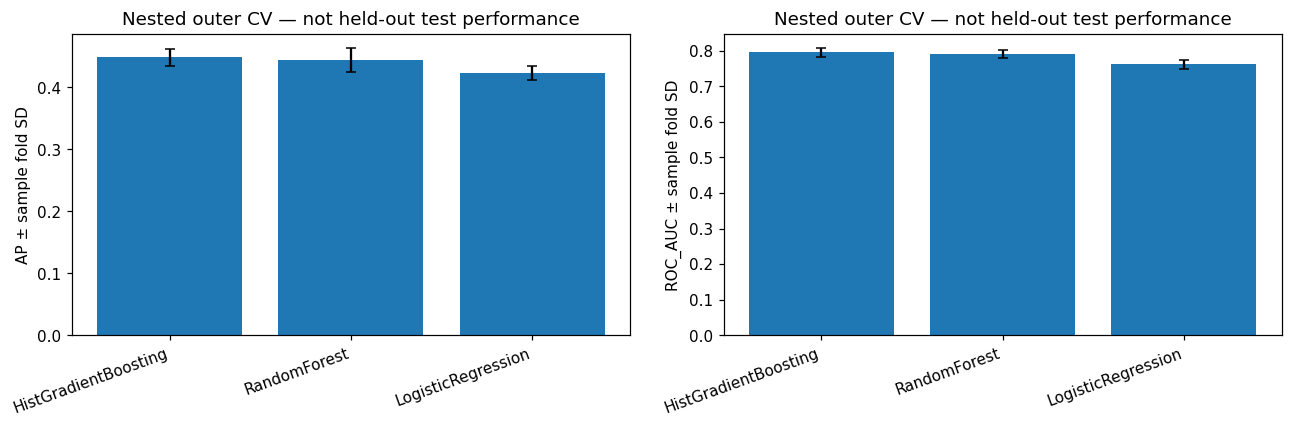

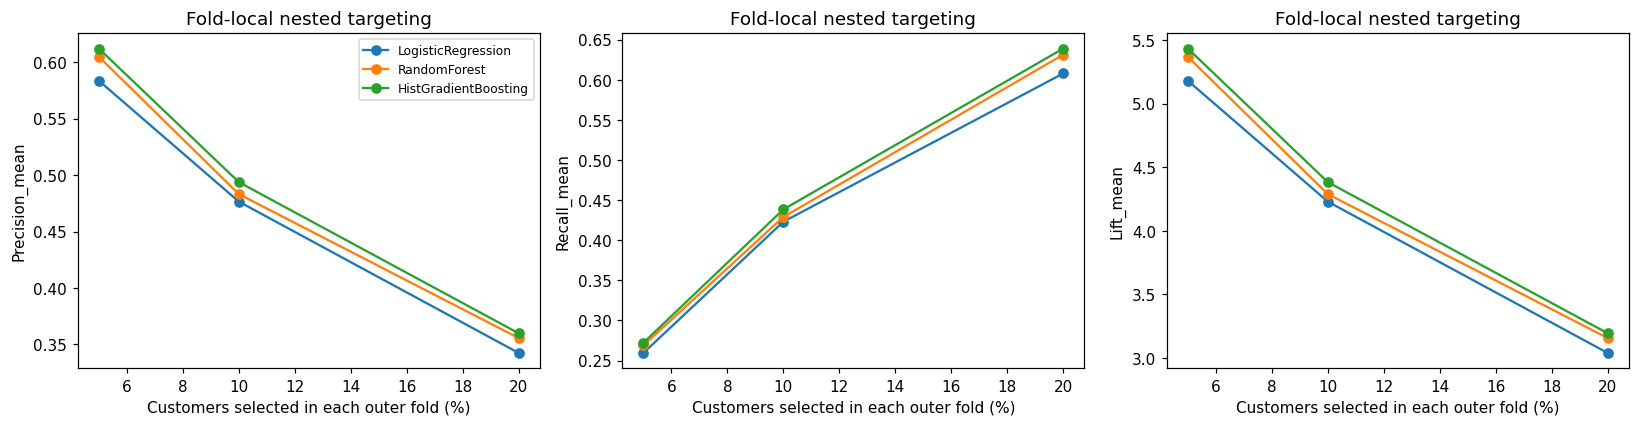

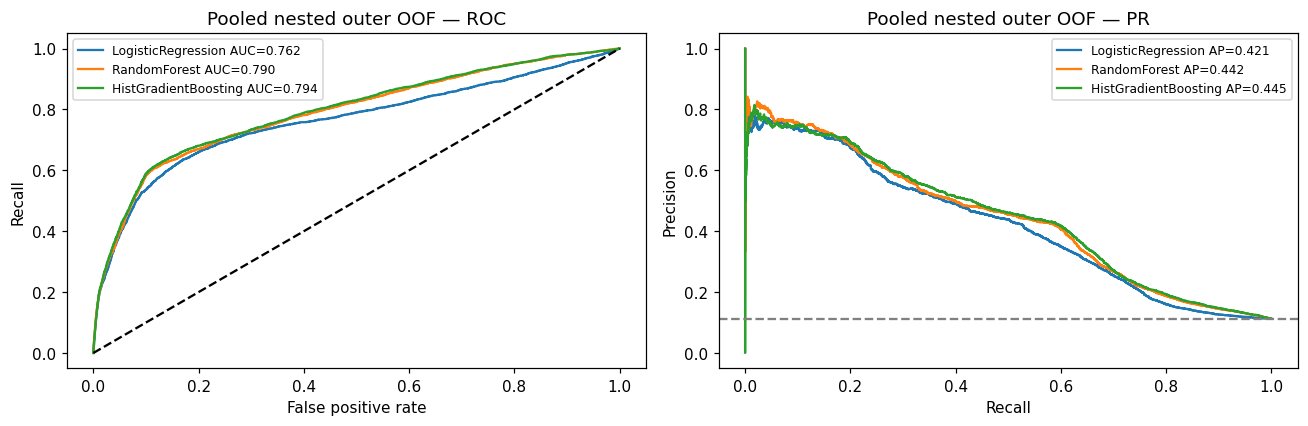

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
order=rank.index.tolist();x=np.arange(3)
for ax,metric in zip(axes,['AP','ROC_AUC']):
    ax.bar(x,means.loc[order,metric],yerr=sds.loc[order,metric],capsize=3)
    ax.set_xticks(x,order,rotation=20,ha='right');ax.set(ylabel=metric+' ± sample fold SD',title='Nested outer CV — not held-out test performance')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['Precision_mean','Recall_mean','Lift_mean']):
    for model in MODELS:
        d=local_summary.loc[local_summary.model.eq(model)];ax.plot(d.fraction*100,d[metric],marker='o',label=model)
    ax.set(xlabel='Customers selected in each outer fold (%)',ylabel=metric,title='Fold-local nested targeting')
axes[0].legend(fontsize=8);plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for model in MODELS:
    prob=oof[model]['prob'];fpr,tpr,_=roc_curve(y,prob);pr,re,_=precision_recall_curve(y,prob)
    axes[0].plot(fpr,tpr,label=f'{model} AUC={roc_auc_score(y,prob):.3f}')
    axes[1].plot(re,pr,label=f'{model} AP={average_precision_score(y,prob):.3f}')
axes[0].plot([0,1],[0,1],'k--');axes[1].axhline(y.mean(),color='gray',ls='--')
axes[0].set(xlabel='False positive rate',ylabel='Recall',title='Pooled nested outer OOF — ROC')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Pooled nested outer OOF — PR')
for ax in axes:ax.legend(fontsize=8)
plt.tight_layout();plt.show()



## 6. Preserve artifacts, audit every fit and report actual results

Verify all supplied input hashes and in-memory development values, summarize 675 inner fits +15 outer refits and corresponding prediction roles, convergence/warnings, runtime and selection stability. Existing standalone preprocessing tests are checked separately. No previous data, split, module, notebook or summary is changed. No fitted artifact or transformed dataset is exported.

All 15 predictors remain Provisional: age, job, marital, education, default, housing, loan, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed, recency_available, recency_days. Pre-campaign snapshots, historical cutoff/recency reference date, economic publication/revision vintage, label window and missing customer/date metadata remain unresolved. Nested tuning does not fix temporal/repeated-client overlap, earlier whole-data EDA exposure or feature-timing leakage. Random-fold performance is not certified future-campaign/unseen-client performance.

Use observed nested AP, capacity-specific capture and cost to propose a Phase 5B shortlist, not a final deployable winner. Business costs/capacity/value and uncertainty/timing assumptions need team review. Stop after Phase 5A without commit or push.


In [6]:
for name,digest in input_hashes.items():assert sha(PROJECT_DIR/name)==digest,name+' modified'
pd.testing.assert_frame_equal(dev,snapshot,check_exact=True)
assert all(a['status']=='PASS' for a in FIT_AUDIT+PRED_AUDIT)
fit_summary=pd.DataFrame(FIT_AUDIT).groupby(['model','role','rows']).size().rename('fits').reset_index()
pred_summary=pd.DataFrame(PRED_AUDIT).groupby(['model','role']).size().rename('probability_calls').reset_index()
cost_summary=cost.groupby('model').agg(candidates_per_outer=('candidates','first'),total_inner_CV_fits=('inner_CV_fits','sum'),
    total_outer_refits=('outer_training_refits','sum'),search_refit_seconds=('search_refit_seconds','sum'),outer_prediction_seconds=('outer_prediction_seconds','sum'))
lr_iterations=pd.DataFrame(FIT_AUDIT).loc[lambda d:d.model.eq('LogisticRegression'),'iterations'].astype(int)
outer_refit_audit=pd.DataFrame(FIT_AUDIT).loc[lambda d:d.role.eq('outer-training refit')]
display(cost);display(cost_summary);display(fit_summary);display(pred_summary);display(outer_refit_audit)
display(pd.DataFrame(WARNING_LOG) if WARNING_LOG else pd.DataFrame({'warnings':['No estimator or convergence warnings recorded']}))
elapsed=time.perf_counter()-started_all

def mdtable(frame,index=False):
    t=frame.reset_index() if index else frame.copy()
    def fmt(v):return f'{v:.6f}' if isinstance(v,(float,np.floating)) else str(v).replace('|',' / ').replace('\n',' ')
    return '\n'.join(['| '+' | '.join(map(str,t.columns))+' |','| '+' | '.join(['---']*len(t.columns))+' |']+['| '+' | '.join(fmt(v) for v in r)+' |' for r in t.itertuples(index=False,name=None)])
warning_text=mdtable(pd.DataFrame(WARNING_LOG)) if WARNING_LOG else 'None recorded across all 690 fits.'
inner_table=pd.DataFrame(inner_manifest)
hgb_difference=means.loc['HistGradientBoosting','AP']-means.loc['RandomForest','AP']
parameter_diversity=stability.groupby('model').size().to_dict()
summary=f"""# Phase 5A — Nested CV and business targeting comparison

## Scope, provenance and data isolation

Started from fetched latest GitHub main **{BASE_MAIN_COMMIT}**, which includes Phase 4B. The local branch was fast-forwarded to that main commit before development; no new merge commit was created. Reviewed preprocessing.py, Phase 2C summaries/split/data, Phase 3 summary, Phase 4 and Phase 4B notebooks/summaries. Existing Decision Tree results remain historical references; DT is not retuned here. No previous result files or approved preprocessing were changed.

Exact cleaned CSV SHA-256 `{input_hashes['02_cleaned_dataset.csv']}` matched saved 03_split_indices.json before applying zero-based row positions. This validates values and row order, not just dimensions. Saved partitions contain 32,940 development and 8,236 held-out positions; unique/disjoint/exhaustive checks passed. Only development CSV rows were parsed and put back into saved development order; held-out feature/label rows were not parsed or used. Original CSV, if present, was only byte-hashed. No new train-test split. Development subscribers: {int(y.sum()):,}, prevalence {float(y.mean()):.6f} ({float(y.mean())*100:.4f}%).

Outer validation-position hash `{outer_hash}` matches Phase 4B's recorded folds. Both outer and inner CV use StratifiedKFold(n_splits=5,shuffle=True,random_state=42), with common outer/inner pairs across the three models. Seeds for every classifier are 42. No class weighting, resampling, feature selection/ablation, threshold optimization, held-out evaluation or Phase 5B work.

Versions: sklearn {sklearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}. Google Colab-compatible notebook requires standard packages and sklearn >=1.2, uploaded preprocessing.py/cleaned CSV/split JSON/Phase 4B summary, or PROJECT_DIR set to mounted Drive. Executed locally, not a live hosted Colab session. threadpoolctl limits native threads to one; GridSearchCV and RF use n_jobs=1.

## Fixed search procedures and nested design

- LR: C=[0.1,1,10], lbfgs/default L2, max_iter=1000, class_weight=None (3 candidates).
- RF: n_estimators=[100,200], max_depth=[10,None], min_samples_leaf=[5,20], max_features='sqrt', class_weight=None (8 candidates).
- HGB: learning_rate=[0.05,0.1], max_iter=[100,200], max_leaf_nodes=[15,31], l2_regularization=[0,1], early_stopping=False, categorical_features=None, class_weight=None (16 candidates).

These exact grids are fixed throughout all outer folds; no outer-result-driven changes. GridSearchCV(scoring=inner_score,refit='AP',cv=inner_folds,n_jobs=1,error_score='raise') selects only by inner Average Precision. The scorer returns the named AP result from positive-class predict_proba. Every search uses only 26,352 outer-training rows, with five inner validation splits (training 21,081/21,082; validation 5,270/5,271). The winner is refitted on all outer-training rows and predicts its 6,588-row untouched outer-validation fold once. There are 675 inner candidate-fold fits plus 15 outer-training refits = **690 fits**; 675 inner-validation probability calls and 15 outer-validation calls. No fitted object ever receives all 32,940 development rows for fitting. No production model was fitted or exported.

Complete pipelines reuse the approved factories. LR retains ordinary numerical scaling and available-only ConditionalRecencyScaler. RF uses its existing unscaled factory; HGB uses the equivalent existing decision_tree factory as approved in Phase 4B, with numeric one-hot indicators (native categorical handling off). An experiment-only stateless finite/representation guard returns arrays unchanged and checks them before classifier fit. Audit wrappers verify every partition and fit/transform state without replacing approved preprocessing. No global encoder/scaler or encoded matrix is cached/shared.

Threshold is fixed at probability >=0.5. Accuracy/precision/recall/F1 use positive class 1, zero_division=0; ROC-AUC/AP use positive probabilities. AP is Average Precision, not trapezoidal PR area. All reported SDs use ddof=1 (sample SD) across five outer-fold values; overlapping training partitions mean these are descriptive spread, not independent confidence intervals or significance tests.

## Individual outer-fold predictive results

{mdtable(outer_results)}

## Nested outer-CV mean ± sample SD

{mdtable(comparison,index=True)}

Nested AP ranking: {', '.join(rank.index)}. Leading mean AP is **{rank.index[0]}: {rank.iloc[0]:.6f}**. HGB minus RF nested mean AP = {hgb_difference:+.6f}. This measured difference describes these fixed-grid procedures under random stratified folds; it is not a significance conclusion or proof of future-campaign performance.

Outer-fold AP leaders:

{mdtable(fold_wins)}

## Fold-specific selected hyperparameters and stability

{mdtable(selections)}

inner_best_AP_selection_only is an inner tuning statistic, never substituted for the outer validation score. Distinct winning configurations across five outer folds: {json.dumps(parameter_diversity,sort_keys=True)}.

{mdtable(stability)}

Different choices show sensitivity to outer-training composition; repeated choices do not establish a universal optimum. No single final hyperparameter configuration is selected or refitted on complete development data here.

## Comparison with previous potentially optimistic selected-CV scores

{mdtable(historical_comparison)}

Previous values are imported from Phase 4B's six-decimal published comparison, not rerun or overwritten. They selected winners and reported scores on the same tuning folds. Current outer scores assess the fixed hyperparameter-selection procedures without using outer validation to choose that fold's hyperparameters. Changes can reflect both prior selection optimism and variation in winners; they do not by themselves quantify all optimism or statistical significance. Prior phases already explored this development set and helped define model families/grids. Nested CV reduces immediate tuning-fold reuse but is not a pristine new external evaluation; selecting a winning family using these outer means also introduces model-selection uncertainty.

## Business targeting — fold-local outer-validation ranks

Use only probabilities from outer-validation predictions. Rank each validation cohort separately. K=ceil(fraction*N), sorting by descending probability then saved cleaned-row position as reproducible, outcome-independent tie-break. Precision@K=captured/K; Recall@K=captured/actual subscribers in that cohort; Lift@K=Precision@K/cohort prevalence. Target fractions 5%,10%,20% were fixed before results. Every model has exactly the same contact capacity within each view/fold. Subscriber counts reflect historical validation outcomes, not causal outreach response or a known financial return.

{mdtable(local)}

Mean and sample SD across the five cohorts (including contact volumes/captured counts):

{mdtable(local_summary)}

Fold-local highest mean Precision@K at each capacity: {json.dumps({str(k):v for k,v in local_winners.items()},sort_keys=True)}. At equal capacity this is also the highest mean captured count (all outer cohorts have equal size). Compare Recall/Lift separately because prevalence varies slightly across cohorts. Mean subscriber capture can be fractional across folds; it is not an actual fractional person.

## Business targeting — pooled nested outer OOF ranks

{mdtable(pooled)}

Pooled highest Precision@K at each capacity: {json.dumps({str(k):v for k,v in pooled_winners.items()},sort_keys=True)}. Pooled contact counts are 1,647/3,294/6,588; fold-local counts are 330/659/1,318 per fold. Ceil rounding makes sums across fold-local cohorts differ slightly from pooled capacities. Do not equate the two ranking views.

Each development observation has exactly one out-of-sample outer prediction, but pooled scores come from five separately tuned/fitted models with potentially different calibration/scales and overlapping training sets. Fold-local rankings are the cleaner comparison at a consistent per-cohort capacity; pooled targeting is an additional development diagnostic, not a single deployable prioritization model. Ties may materially change coarse ranks; no labels determine their ordering. Broader groups may capture more subscribers at lower precision/lift; use the actual tables rather than assume monotonic precision. Costs, product value, operational capacity and treatment effects are unknown, so no financial optimum is claimed.

Pooled predictive diagnostics (not a substitute for mean outer metrics):

{mdtable(pooled_diagnostic)}

## Computational costs and practical trade-offs

{mdtable(cost)}

{mdtable(cost_summary,index=True)}

Total elapsed through experiments/plots: {elapsed:.2f} seconds on this runtime, not a promised Colab time. Wall times include fold auditing and selected outer-training refits. RF/HGB explore more candidates than LR; cost should be considered alongside observed AP, targeting and stability, not just a nominal complexity ranking. No candidate grid was reduced or expanded. LR remains useful as a simpler log-odds/linear reference; one-hot coding and correlated indicators still complicate coefficients. Nonlinear ensembles may add targeting value but that must be judged from these measurements, not assumed from complexity.

## Technical audit evidence

{mdtable(fit_summary)}

{mdtable(pred_summary)}

Outer-training selected-model refit audits (not in-sample performance):

{mdtable(outer_refit_audit)}

All 690 fresh preprocessing fits passed. Each inner training partition is disjoint from its paired inner validation and the current outer validation; inner splits are regenerated reproducibly within each outer-training partition and reused for all models. All outer folds have disjoint training/validation rows and complete exactly-once OOF coverage. Stored indices never overlap held-out positions. Audit wrappers reject whole-development fitting and reject any outer-validation prediction during inner scoring. Correct row-aligned targets, classifier classes/probabilities, class_weight=None and fixed seeds are checked.

Every OHE vocabulary equals its fitting rows' levels only. LR StandardScaler mean/variance/scale/sample count matches the corresponding fitting subset. Conditional recency mean/variance/scale/count uses only available-recency fitting rows, with unavailable standardized values zero and the indicator unscaled. Existing zero-variance/insufficient-sample fallback code remains unchanged; all four original standalone preprocessing tests passed when rerun separately. Tree/HGB transformed numbers exactly equal validation input, preserving zeros/availability and excluding 999. Finite representation is checked before training and at every prediction; coefficients/probability-derived outputs and all final metric/ranking tables contain no NaN/infinity. Fitted state is unchanged by each validation transform. HGB retains numeric indicators, disabled early stopping and its fixed iteration budget. All datasets, saved split, preprocessing and earlier results remain unchanged by hash and in-memory equality checks.

LR fitted iteration range over its inner/outer fits: {int(lr_iterations.min())}–{int(lr_iterations.max())}, max_iter=1000. Warnings/errors:

{warning_text}

No corrective grid/preprocessing changes were silently made. Inner fold validation-position hashes, complete fit audit records, the most recent search object and all OOF arrays are retained in notebook memory during execution; no fitted estimators or new datasets are exported. The displayed tables/plots preserve the results when the notebook is saved.

## Provisional recommendations and Phase 5B approval

Use the nested AP ordering **{', '.join(rank.index)}**, fold-local and pooled capacity-specific winners, and the measured cost tables to shortlist procedures. Advance the leading nested-AP family **{rank.index[0]}** for review alongside the closest nonlinear competitor, retaining **Logistic Regression** as a transparent/simple reference. Do not automatically declare the highest mean a significant winner. Assess whether its marginal subscriber capture at a feasible contact budget justifies computational/operational complexity. The capacity-specific winners may differ from the global AP leader.

All 15 predictors remain Provisional: {', '.join(FEATURES)}. Confirm campaign-start customer/financial snapshots, historical-contact cutoff and recency reference dates, economic publication/revision vintage, and label outcome/follow-up window. Random stratified CV cannot eliminate repeated-customer or temporal overlap without missing customer IDs/dates. Prior whole-dataset EDA exposure persists. Nested tuning prevents direct inner/outer selection contamination; it does not certify feature-timing safety, unseen-client/future-campaign generalization, deployment readiness or causal effect of outreach.

Team approval still needed: model shortlist/business targeting capacity and error/call value assumptions; whether observed differences merit paired uncertainty analysis rather than significance claims; timing metadata/acceptable academic assumptions; client/time validation requirements; and the scope of Phase 5B. No class weights, resampling, threshold optimization, feature selection/ablation, held-out evaluation, Phase 5B, commit or push occurred.

Deliverables: executed 06_nested_cv_targeting.ipynb and this 06_nested_cv_targeting_summary.md in the repository. Stop after Phase 5A pending approval.
"""
(PROJECT_DIR/'06_nested_cv_targeting_summary.md').write_text(summary)
print('Saved Phase 5A summary; all boundaries preserved. No commit/push or Phase 5B.')


Saved Phase 5A summary; all boundaries preserved. No commit/push or Phase 5B.


,model,outer_fold,candidates,inner_CV_fits,outer_training_refits,search_refit_seconds,outer_prediction_seconds
0,LogisticRegression,1,3,15,1,1.548229,0.023019
1,RandomForest,1,8,40,1,78.988955,0.089764
2,HistGradientBoosting,1,16,80,1,77.513013,0.046056
3,LogisticRegression,2,3,15,1,1.512575,0.018960
4,RandomForest,2,8,40,1,76.941852,0.094189
5,HistGradientBoosting,2,16,80,1,78.906073,0.042657
6,LogisticRegression,3,3,15,1,1.564975,0.019266
7,RandomForest,3,8,40,1,80.054255,0.064710
8,HistGradientBoosting,3,16,80,1,80.486319,0.045566
9,LogisticRegression,4,3,15,1,1.619060,0.018728


,candidates_per_outer,total_inner_CV_fits,total_outer_refits,search_refit_seconds,outer_prediction_seconds
model,,,,,
HistGradientBoosting,16,400,5,403.880552,0.218705
LogisticRegression,3,75,5,7.879538,0.110568
RandomForest,8,200,5,395.841682,0.416164


,model,role,rows,fits
0,HistGradientBoosting,inner-training fit,21081,160
1,HistGradientBoosting,inner-training fit,21082,240
2,HistGradientBoosting,outer-training refit,26352,5
3,LogisticRegression,inner-training fit,21081,30
4,LogisticRegression,inner-training fit,21082,45
5,LogisticRegression,outer-training refit,26352,5
6,RandomForest,inner-training fit,21081,80
7,RandomForest,inner-training fit,21082,120
8,RandomForest,outer-training refit,26352,5


,model,role,probability_calls
0,HistGradientBoosting,inner validation,400
1,HistGradientBoosting,outer validation,5
2,LogisticRegression,inner validation,75
3,LogisticRegression,outer validation,5
4,RandomForest,inner validation,200
5,RandomForest,outer validation,5


,outer_fold,model,role,inner_fold,rows,observed_recency,recency_mean,recency_scale,iterations,warnings,status
15,1,LogisticRegression,outer-training refit,all outer training,26352,947,6.07075,3.843597,58,0,PASS
56,1,RandomForest,outer-training refit,all outer training,26352,947,unscaled,unscaled,not applicable,0,PASS
137,1,HistGradientBoosting,outer-training refit,all outer training,26352,947,unscaled,unscaled,100,0,PASS
153,2,LogisticRegression,outer-training refit,all outer training,26352,957,6.022989,3.855744,56,0,PASS
194,2,RandomForest,outer-training refit,all outer training,26352,957,unscaled,unscaled,not applicable,0,PASS
275,2,HistGradientBoosting,outer-training refit,all outer training,26352,957,unscaled,unscaled,100,0,PASS
291,3,LogisticRegression,outer-training refit,all outer training,26352,967,6.024819,3.885566,55,0,PASS
332,3,RandomForest,outer-training refit,all outer training,26352,967,unscaled,unscaled,not applicable,0,PASS
413,3,HistGradientBoosting,outer-training refit,all outer training,26352,967,unscaled,unscaled,100,0,PASS
429,4,LogisticRegression,outer-training refit,all outer training,26352,978,6.208589,3.993022,56,0,PASS


,warnings
0,No estimator or convergence warnings recorded


## Observed completion review

HGB led AP in four of five outer folds and its nested mean AP exceeds RF by 0.004215, small relative to fold SDs. It led both fold-local and pooled targeting at 5%, 10% and 20%; pooled gains over RF were 6, 40 and 36 subscribers respectively. These are modest historical predictive differences, not significance or causal outreach claims.

LR chose C=0.1 in all folds, HGB consistently chose learning_rate=0.05 / 100 iterations / 15 leaves (two L2 values), and RF chose four configurations. LR is far cheaper in this measured run but trails on AP and targeting. Keep HGB and RF on the Phase 5B review shortlist, with LR as a simpler reference; no final configuration or next phase is authorized here. All four existing preprocessing tests passed. All 690 fits completed without model warnings; original data, split and earlier artifacts remain unchanged.
